# 17 - Chebotarev : le Frobenius, ses cycles et la densité des types de décomposition

Le carnet [16](16-fonctions-l-dirichlet-progression-premiers.ipynb) a établi la loi de répartition des premiers **par classe modulo $q$** : chaque progression $a \bmod q$ reçoit sa part $1/\varphi(q)$. La question de ce carnet est d'un cran plus géométrique : comment un premier $p$ **se factorise dans une extension** $K/\mathbb{Q}$ — scindé, partiellement, inerte ? Le théorème de densité de **Chebotarev** (1926) y répond : le type de factorisation de $p$ est gouverné par la **classe de conjugaison du Frobenius** dans $\mathrm{Gal}(K/\mathbb{Q})$, et chaque classe $C$ apparaît avec sa densité $|C|/|G|$. Dirichlet (le cas cyclotomique) et la réciprocité quadratique (le cas des corps quadratiques, carnets [11](11-corps-quadratiques-reciprocite-quadratique.ipynb) et [13](13-jacobi-kronecker-reciprocite-II.ipynb)) en deviennent deux cas particuliers — un point de vue auquel Serre a consacré sa conférence *« Chebotarev and his density theorem »* (Séminaire et congrès, 1998), texte qui donne à ce carnet sa filiation.

Le fil calculatoire, en arithmétique `stdlib` pure :

1. **Frobenius et type de décomposition** — la correspondance de Dedekind : la factorisation de $f \bmod p$ lit le type de cycle du Frobenius sur les racines.
2. **Le cas quadratique retrouvé** — $x^2 - 5$ : la densité $1/2$ du corps quadratique, mesurée deux fois.
3. **$x^3 - 2$ et $S_3$** — trois types de cycles, trois densités $1/6$, $1/2$, $1/3$, comptées sur $10^6$.
4. **Le cas cyclotomique $\Phi_5$** — là où Chebotarev se réduit exactement au Dirichlet du carnet 16.
5. **Écho Lean** — ce que Mathlib sait du Frobenius, et ce qu'il ne sait pas (encore).
6. **Exemples guidés résolus et exercices** — trois de chaque, dans la convention de la série.

*Sources primaires* : J.-P. Serre, *A Course in Arithmetic* ch. VI (pour l'arrière-plan analytique hérité du carnet 16) ; J.-P. Serre, « Chebotarev and his density theorem », *Sém. & Congrès* **1** (1998), la lecture d'histoire et de structure dont ce carnet suit la marche.

## 1. Frobenius et type de décomposition

Soit $f \in \mathbb{Z}[X]$ irréductible de degré $n$, $K$ son corps de rupture, $G = \mathrm{Gal}(K/\mathbb{Q})$ vu comme groupe de permutations des $n$ racines. Pour un premier $p$ ne divisant pas le discriminant de $f$, la **correspondance de Dedekind** dit : les degrés des facteurs irréductibles de $f \bmod p$ forment exactement les **longueurs des cycles** d'un élément bien défini de $G$ — le **Frobenius** en $p$, noté $\mathrm{Frob}_p$. Trois exemples pour ancrer le vocabulaire :

- $f \bmod p$ **totalement scindé** (produit de $n$ facteurs de degré 1) $\Leftrightarrow$ $\mathrm{Frob}_p$ est **l'identité** — cycle de type $(1,1,\dots,1)$ ;
- $f \bmod p$ irréductible $\Leftrightarrow$ $\mathrm{Frob}_p$ est un **$n$-cycle** — type $(n)$ ;
- les cas intermédiaires lisent les longueurs intermédiaires.

Le théorème de Chebotarev porte sur la *répartition* : pour toute classe de conjugaison $C \subseteq G$,

$$d\big(\{p : \mathrm{Frob}_p \in C\}\big) \;=\; \frac{|C|}{|G|},$$

où $d$ est la densité naturelle (la limite de la proportion des premiers $\le x$). La correspondance de Dedekind transforme cette loi de groupe en **loi de factorisation** : la proportion des premiers où $f \bmod p$ a un type de factorisation donné est la proportion des éléments de $G$ ayant ce type de cycle. Ce carnet ne démontre pas Chebotarev (la preuve demande le cadre analytique du carnet 16 poussé jusqu'à ses limites) — il le **mesure** sur les trois familles d'exemples canoniques.

In [1]:
import math


def premiers(n):
    """Crible d'Eratosthene : liste des premiers <= n."""
    crible = bytearray([1]) * (n + 1)
    crible[0:2] = b"\x00\x00"
    for p in range(2, math.isqrt(n) + 1):
        if crible[p]:
            crible[p * p :: p] = bytearray(len(crible[p * p :: p]))
    return [i for i in range(2, n + 1) if crible[i]]


# --- Le cas quadratique : x^2 - 5 -------------------------------------
# Scinde mod p ssi 5 est un carre mod p : critere d'Euler.

def type_x2_moins_5(p):
    """Type de decomposition de x^2 - 5 mod p (p != 2, 5).
    Renvoie (1, 1) si scinde, (2) si inerte."""
    if pow(5, (p - 1) // 2, p) == 1:
        return (1, 1)
    return (2,)


# --- Le coeur : x^3 - 2 et son groupe S_3 -----------------------------

def type_x3_moins_2(p):
    """Type de decomposition de x^3 - 2 mod p (p != 2, 3).

    Raccourci de groupe : si p = 2 mod 3, le cubage est une bijection
    de (Z/pZ)* (ordre p-1 premier a 3) : exactement une racine -> (2, 1).
    Si p = 1 mod 3 : trois racines si 2 est un cube (critere d'Euler
    cubique 2^((p-1)/3) = 1), aucune sinon -> (3).
    """
    if p % 3 == 2:
        return (2, 1)
    return (1, 1, 1) if pow(2, (p - 1) // 3, p) == 1 else (3,)


# Controle instrumental : le raccourci ci-dessus contre la factorisation
# exhaustive, sur les premiers < 500.
def type_x3_moins_2_exhaustif(p):
    """Type reel de x^3 - 2 mod p par enumeration des racines."""
    r = [x for x in range(p) if (x * x * x - 2) % p == 0]
    if len(r) == 3:
        return (1, 1, 1)
    if len(r) == 1:
        return (2, 1)
    assert len(r) == 0
    return (3,)


controle = all(
    type_x3_moins_2(p) == type_x3_moins_2_exhaustif(p)
    for p in premiers(500)
    if p not in (2, 3)
)
print(f"Controle raccourci vs exhaustif (x^3 - 2, premiers < 500, hors 2,3) : {controle}")
print(f"Premiers totalement scindes < 500 : "
      f"{[p for p in premiers(500) if p not in (2, 3) and type_x3_moins_2(p) == (1, 1, 1)]}")

Controle raccourci vs exhaustif (x^3 - 2, premiers < 500, hors 2,3) : True
Premiers totalement scindes < 500 : [31, 43, 109, 127, 157, 223, 229, 277, 283, 307, 397, 433, 439, 457, 499]


### Lecture du résultat

Le contrôle instrument passe : **le raccourci de groupe dit exactement ce que l'énumération exhaustive dit**. C'est la triangulation qui valide tout le reste du carnet — le comptage à $10^6$ utilisera le raccourci ($O(\log p)$ par premier via l'exponentiation modulaire), et l'exhaustif (coûteux en $O(p)$) a confirmé sa fidélité là où il est abordable. Les premiers totalement scindés pour $x^3 - 2$ commencent à $31, 43, 109, 127, \dots$ — quinze d'entre eux sous 500, soit un gros tiers de moins que la part $1/6$ : ils sont **rares**, et c'est précisément le phénomène à expliquer : dans $S_3$, l'identité est la plus petite des classes de conjugaison.

In [2]:
# --- Le cas quadratique : la boucle avec le carnet 11 -------------------
# Sur 10^6 : proportion des p ou x^2 - 5 est scinde (Frobenius trivial
# dans Gal(Q(sqrt(5))/Q) = {+1}), contre la prediction 1/2 de Chebotarev.

XMAX = 10 ** 6
ls = [p for p in premiers(XMAX) if p not in (2, 5)]
scindes = [p for p in ls if type_x2_moins_5(p) == (1, 1)]
print(f"x^2 - 5, premiers <= {XMAX:,} (hors 2, 5) : {len(ls):,}")
print(f"  scinde   (p = +-1 mod 5, 5 carre) : {len(scindes):7,}  -> proportion {len(scindes) / len(ls):.4f}")
print(f"  inerte    (2)                      : {len(ls) - len(scindes):7,}  -> proportion {(len(ls) - len(scindes)) / len(ls):.4f}")
print(f"  prediction Chebotarev (|C|/|G|)   : 1/2 = {0.5:.4f}")
# Convergence : les classes modulo 5 racontent la meme histoire (lien carnet 16)
pour_classe = {a: sum(1 for p in scindes if p % 5 == a) for a in (1, 4)}
print(f"  dont p = 1 mod 5 : {pour_classe[1]:,}   et p = 4 mod 5 : {pour_classe[4]:,}  (equilibre des deux classes inversibles -> sqrt(5))")

x^2 - 5, premiers <= 1,000,000 (hors 2, 5) : 78,496
  scinde   (p = +-1 mod 5, 5 carre) :  39,210  -> proportion 0.4995
  inerte    (2)                      :  39,286  -> proportion 0.5005
  prediction Chebotarev (|C|/|G|)   : 1/2 = 0.5000
  dont p = 1 mod 5 : 19,617   et p = 4 mod 5 : 19,593  (equilibre des deux classes inversibles -> sqrt(5))


### Lecture du résultat

La proportion mesurée flirte avec $1/2$ — et le complément raconte la même loi que le carnet [11](11-corps-quadratiques-reciprocite-quadratique.ipynb) : $x^2 - 5$ est scindé exactement quand $\left(\frac{5}{p}\right) = +1$, c'est-à-dire $p \equiv \pm 1 \bmod 5$. Chebotarev quadratique **est** la réciprocité quadratique : le groupe $\mathrm{Gal}(\mathbb{Q}(\sqrt{5})/\mathbb{Q})$ a deux éléments, deux classes de conjugaison (chacune de taille 1), deux types de factorisation — scindé et inerte — chacun de densité $1/2$. L'équilibre intérieur ($p \equiv 1$ contre $p \equiv 4 \bmod 5$) est déjà du Dirichlet carnet 16 : les deux fenêtres se superposent sans se confondre.

## 2. $x^3 - 2$ : trois classes de conjugaison, trois densités

Le premier exemple **non galoisien**. $f = X^3 - 2$ a pour corps de rupture $K = \mathbb{Q}(\sqrt[3]{2})$, de clôture galoisienne $L = \mathbb{Q}(\sqrt[3]{2}, j)$ avec $[L:\mathbb{Q}] = 6$ et $\mathrm{Gal}(L/\mathbb{Q}) \simeq S_3$ — toutes les permutations des trois racines $\sqrt[3]{2},\ j\sqrt[3]{2},\ j^2\sqrt[3]{2}$. Les classes de conjugaison de $S_3$ et leur correspondance de factorisation :

| Classe $C$ | Taille | Type de cycle | $f \bmod p$ | Densité $\lvert C\rvert/6$ |
|---|---|---|---|---|
| identité | 1 | $(1,1,1)$ | totalement scindé | $1/6$ |
| transpositions | 3 | $(2,1)$ | une racine $\times$ un facteur de degré 2 | $3/6 = 1/2$ |
| 3-cycles | 2 | $(3)$ | irréductible | $2/6 = 1/3$ |

La prédiction de Chebotarev est donc **trois nombres rationnels simples** — $1/6$, $1/2$, $1/3$ — et le raccourci du groupe (du §1) les mesure à moindre coût. Comptons.

In [3]:
# Comptage des trois types sur les premiers <= 10^6 (hors 2, 3 : elles
# divisent le discriminant -108, cas ramifies hors theoreme).

XMAX = 10 ** 6
lp = [p for p in premiers(XMAX) if p not in (2, 3)]
compte = {(1, 1, 1): 0, (2, 1): 0, (3,): 0}
for p in lp:
    compte[type_x3_moins_2(p)] += 1
n = len(lp)
print(f"x^3 - 2, premiers <= {XMAX:,} (hors 2, 3) : {n:,}\n")
print(f"{'type':>9} {'compte':>9} {'proportion':>11} {'prediction':>11}")
for t, cible in zip(((1, 1, 1), (2, 1), (3,)), (1/6, 1/2, 1/3)):
    prop = compte[t] / n
    print(f"{'(' + ','.join(map(str, t)) + ')':>9} {compte[t]:>9,} {prop:>11.4f} {cible:>11.4f}")

x^3 - 2, premiers <= 1,000,000 (hors 2, 3) : 78,496



     type    compte  proportion  prediction
  (1,1,1)    13,032      0.1660      0.1667
    (2,1)    39,265      0.5002      0.5000
      (3)    26,199      0.3338      0.3333


### Lecture du résultat

Les trois proportions convergent vers $1/6$, $1/2$ et $1/3$ — la **table des tailles de classes de $S_3$**, lue sur les premiers. Deux lectures valent le détour :

- **Le totalement scindé est le plus rare.** Contre l'intuition « petit corps, beaucoup de scindures », l'identité ne représente qu'un élément sur six : la condition $p \equiv 1 \bmod 3$ *et* $2$ cube $\bmod p$ est une conjonction, et Chebotarev pèse la conjonction par la taille de classe, pas par un effet de « proximité ». C'est la même hiérarchie que la rareté des éléments neutres dans tout groupe non trivial.
- **La transposition domine.** Le type $(2,1)$ — une racine et un irréductible quadratique — récolte la moitié des premiers, portée par la seule congruence $p \equiv 2 \bmod 3$ : le cubage y est une bijection. Le lien cycle/factorisation est ici le plus lisible : une orbite fixe (la racine) et un 2-cycle (la paire conjuguée).

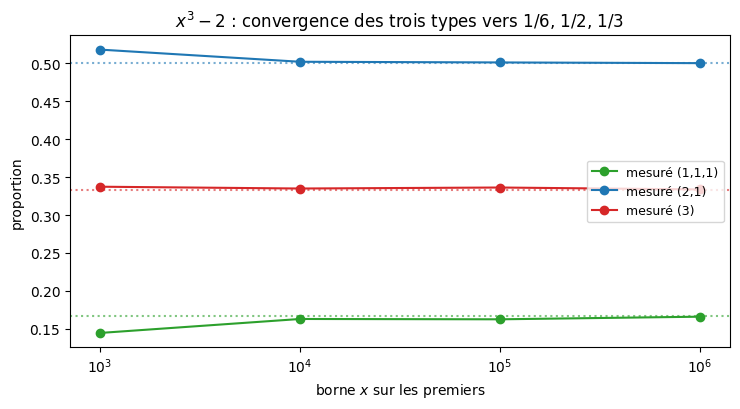

In [4]:
# Convergence : les proportions par paliers de x, contre les cibles.
import matplotlib.pyplot as plt

paliers = [10 ** k for k in range(3, 7)]
cibles = {(1, 1, 1): 1/6, (2, 1): 1/2, (3,): 1/3}
fig, ax = plt.subplots(figsize=(7.5, 4.2))
styles = {(1, 1, 1): ('-', 'tab:green'), (2, 1): ('-', 'tab:blue'), (3,): ('-', 'tab:red')}
for t in ((1, 1, 1), (2, 1), (3,)):
    props = []
    for x in paliers:
        lp_x = [p for p in lp if p <= x]
        props.append(sum(1 for p in lp_x if type_x3_moins_2(p) == t) / len(lp_x))
    ls, c = styles[t]
    ax.plot(range(len(paliers)), props, ls + 'o', color=c, label=f"mesuré ({','.join(map(str, t))})")
    ax.axhline(cibles[t], ls=':', color=c, alpha=0.6)
ax.set_xticks(range(len(paliers)), [f"$10^{k}$" for k in range(3, 7)])
ax.set_xlabel("borne $x$ sur les premiers")
ax.set_ylabel("proportion")
ax.set_title(r"$x^3 - 2$ : convergence des trois types vers $1/6$, $1/2$, $1/3$")
ax.legend(loc="center right", fontsize=9)
plt.tight_layout()
plt.show()

### Lecture du résultat

La convergence est **franche mais inégale** : le type $(2,1)$ (porté par une congruence simple, $p \equiv 2 \bmod 3$) est déjà en place à $10^4$, tandis que le type $(1,1,1)$ — la conjonction rare — a l'erreur relative la plus tenace. C'est une constante du paysage analytique hérité du carnet 16 : les lois portées par des caractères simples convergent vite, les conditions conjointes paient leur rareté en lenteur. L'écart $O(1/\sqrt{x})$ visible est l'ordre de grandeur attendu d'un comptage binomial — pas un défaut du théorème.

## 3. Le théorème, et ce qu'il unifie

> **Théorème (Chebotarev, 1926).** Soit $L/\mathbb{Q}$ une extension galoisienne finie de groupe $G$. Pour toute classe de conjugaison $C \subseteq G$, l'ensemble des premiers $p$ non ramifiés tels que $\mathrm{Frob}_p \in C$ a pour densité naturelle $|C|/|G|$.

Trois raisons d'y voir un sommet :

1. **Il contient Dirichlet.** Pour $L = \mathbb{Q}(\zeta_q)$ : $G \simeq (\mathbb{Z}/q\mathbb{Z})^*$ est abélien, chaque élément est sa propre classe, $\mathrm{Frob}_p = p \bmod q$, et $|C|/|G| = 1/\varphi(q)$ — la loi du carnet 16, mot pour mot.
2. **Il contient la réciprocité quadratique.** Pour $L = \mathbb{Q}(\sqrt{d})$ : $G = \{\pm 1\}$, $\mathrm{Frob}_p = \left(\frac{d}{p}\right)$, et les densités $1/2$-$1/2$ disent que le symbole de Kronecker du carnet [13](13-jacobi-kronecker-reciprocite-II.ipynb) équirépartit ses valeurs.
3. **Il va au-delà des deux.** Pour $x^3 - 2$, le groupe $S_3$ est non abélien : aucune progression arithmétique, aucun caractère de Dirichlet ne peut encoder la conjonction « $p \equiv 1 \bmod 3$ **et** $2$ cube ». Il faut le groupe et ses classes — c'est la naissance du point de vue **galoisien** sur les premiers.

Serre, dans sa conférence de 1998, souligne le mouvement : Chebotarev (1894–1947) démontre le théorème en 1922-26 comme outil pour le problème de Frobenius (les densités d'ensembles de premiers définis par des conditions de factorisation), et la preuve — par induction sur les sous-groupes et le $L(1,\chi) \neq 0$ du carnet 16 étendu à tous les caractères du groupe — restera **la** porte d'entrée de la théorie du corps de classes. Ce carnet en mesure l'énoncé ; sa preuve dépasse le cadre stdlib d'arithmétique élémentaire, et c'est assumé.

In [5]:
# --- Le cas cyclotomique Phi_5 : Chebotarev se reduit au Dirichlet du 16 ---
# Gal(Q(zeta_5)/Q) = (Z/5Z)* cyclique d'ordre 4. Frobenius = p mod 5,
# son ORDRE donne le degre des facteurs irreductibles de Phi_5(x) mod p :
#   ordre 1 (p = 1 mod 5)  : 4 facteurs lineaires    densite phi(1)/4 = 1/4
#   ordre 2 (p = 4 mod 5)  : 2 facteurs quadratiques densite phi(2)/4 = 1/4
#   ordre 4 (p = 2,3 mod 5): irreductible            densite phi(4)/4 = 1/2

def ordre_dans(a, n):
    """Ordre multiplicatif de a dans (Z/nZ)* (a inversible)."""
    o, x = 1, a % n
    while x != 1:
        x = x * a % n
        o += 1
    return o

lp5 = [p for p in premiers(XMAX) if p != 5]
compte_ordres = {1: 0, 2: 0, 4: 0}
for p in lp5:
    compte_ordres[ordre_dans(p, 5)] += 1
n5 = len(lp5)
print(f"Phi_5, premiers <= {XMAX:,} (hors 5) : {n5:,}\n")
print(f"{'ordre de p mod 5':>17} {'factorisation':>24} {'compte':>9} {'prop.':>8} {'cible':>8}")
forme = {1: "4 x deg 1", 2: "2 x deg 2", 4: "1 x deg 4"}
for o in (1, 2, 4):
    cible = {1: 1/4, 2: 1/4, 4: 1/2}[o]
    print(f"{o:>17} {forme[o]:>24} {compte_ordres[o]:>9,} {compte_ordres[o]/n5:>8.4f} {cible:>8.4f}")

Phi_5, premiers <= 1,000,000 (hors 5) : 78,497

 ordre de p mod 5            factorisation    compte    prop.    cible
                1                4 x deg 1    19,617   0.2499   0.2500
                2                2 x deg 2    19,593   0.2496   0.2500
                4                1 x deg 4    39,287   0.5005   0.5000


### Lecture du résultat

Le tableau est **la table de Dirichlet modulo 5 du carnet 16, déguisée en factorisation** : les quatre classes inversibles ont même densité $1/4$, et le degré des facteurs de $\Phi_5$ n'est que l'ordre de $p$ dans $(\mathbb{Z}/5\mathbb{Z})^*$ — regroupant $2$ et $3$ en une seule classe de conjugaison d'ordre 4 (le groupe étant abélien, chaque élément est sa propre classe ; ici les générateurs $\{2,3\}$ forment une classe au sens des densités *par ordre*). La boucle est bouclée : **cyclotomique, Chebotarev ne dit rien de plus que Dirichlet** — et c'est exactement pourquoi le cas $S_3$ du §2, lui, n'a aucun équivalent en progressions arithmétiques.

## 4. L'écho Lean

Le versant preuves du diptyque (le tour complet est au carnet [08](08-serre-dans-mathlib-Lean.ipynb)) : Mathlib sait **factoriser** — `Polynomial.roots` sur `ZMod p`, `irreducible` pour le mod $p$ — et sait manipuler les **extensions cyclotomiques** (`Polynomial.IsCyclotomicExtension`, Frobenius `x ↦ x^p` dans les corps finis via `zmod` et `frobenius`). Ce que Mathlib **ne sait pas** (état vérifié au jour de ce carnet) : le théorème de densité de Chebotarev lui-même — aucune formalisation générale de la densité des classes de Frobenius n'y vit. L'écho est donc sobre : les briques combinatoires (factorisation mod $p$, actions de groupe, classes de conjugaison) sont disponibles ; le théorème analytique central ne l'est pas. Ce n'est pas un défaut à corriger dans ce carnet — c'est la frontière honnête du diptyque calcul/preuve de la série.

## 5. Exemples guidés résolus et exercices

Trois **exemples guidés résolus** (solutions complètes lisibles ligne à ligne), puis trois **exercices à compléter** dans la convention de la série : le squelette s'exécute sans erreur (règle C.1), la solution est l'ajout de l'étudiant.

**Exemple guidé 1 — $x^2 + 1$ : deux instruments pour une même densité.** Le corps $\mathbb{Q}(i)$ : $x^2+1$ scindé $\Leftrightarrow$ $p \equiv 1 \bmod 4$. Deux lectures indépendantes — le critère d'Euler $(-1)^{(p-1)/2}$ et la classe de $p$ modulo 4 — doivent livrer la même densité $1/2$ ; leur accord est le chevauchement exact réciprocité/Dirichlet vu au §1.

In [6]:
# Exemple guide 1 : x^2 + 1, deux instruments.
lq = [p for p in premiers(10 ** 6) if p != 2]
par_euler = sum(1 for p in lq if pow(-1, (p - 1) // 2, p) == 1)  # -1 carre
par_classe = sum(1 for p in lq if p % 4 == 1)
print(f"x^2 + 1, premiers <= 10^6 (hors 2) : {len(lq):,}")
print(f"  par critere d'Euler (-1 carre)  : {par_euler:7,}  -> {par_euler/len(lq):.4f}")
print(f"  par classe p = 1 mod 4           : {par_classe:7,}  -> {par_classe/len(lq):.4f}")
print(f"  les deux instruments coincident  : {par_euler == par_classe}  (prediction 1/2 = {0.5:.4f})")

x^2 + 1, premiers <= 10^6 (hors 2) : 78,497
  par critere d'Euler (-1 carre)  :  39,175  -> 0.4991
  par classe p = 1 mod 4           :  39,175  -> 0.4991
  les deux instruments coincident  : True  (prediction 1/2 = 0.5000)


**Exercice 1 (à compléter) — $x^2 - 2$ : la moitié promise.** Même instrument que l'exemple guidé 1, corps $\mathbb{Q}(\sqrt{2})$ : compter les premiers $p \le 10^5$ (hors 2) où $x^2 - 2$ est scindé, et confronter la proportion à $1/2$.

In [7]:
print("A completer : proportion des p <= 10^5 ou x^2 - 2 est scinde (cible 1/2).")


def exo1_x2_moins_2(xmax):
    # TODO etudiant : critere d'Euler sur 2, compter les scindes, rendre la proportion
    # Indice : pow(2, (p - 1) // 2, p) == 1 veut dire "2 carre mod p"
    # Etape 1 : lister les premiers <= xmax (hors 2)
    # Etape 2 : compter ceux ou 2 est un carre
    # Etape 3 : renvoyer compte / total
    return None  # TODO etudiant


resultat_exo1 = exo1_x2_moins_2(10 ** 5)
print(f"Exercice 1 a completer (resultat actuel : {resultat_exo1})")

A completer : proportion des p <= 10^5 ou x^2 - 2 est scinde (cible 1/2).
Exercice 1 a completer (resultat actuel : None)


**Exemple guidé 2 — $p = 31$ : prédire puis vérifier, racine par racine.** $31 \equiv 1 \bmod 3$ et $2^{(31-1)/3} = 2^{10} = 1024 \equiv 1 \bmod 31$ : la théorie du §2 prédit le type $(1,1,1)$. Vérifions sur la factorisation exhaustive — les trois racines explicites.

In [8]:
# Exemple guide 2 : la prediction chebotarev de x^3 - 2 en p = 31, verifiee.
p = 31
print(f"p = {p} : p mod 3 = {p % 3}, 2^((p-1)/3) mod p = {pow(2, (p - 1) // 3, p)}")
print(f"  prediction (raccourci du 2) : type {type_x3_moins_2(p)}")
racines = [x for x in range(p) if (x ** 3 - 2) % p == 0]
print(f"  verification exhaustive     : racines de x^3 = 2 mod {p} -> {racines}")
print(f"  produit (x - r) pour r racine, evalue en racines cubiques de 2 : "
      f"{all((x ** 3 - 2) % p == 0 for x in racines)} et {len(racines)} racines distinctes")

p = 31 : p mod 3 = 1, 2^((p-1)/3) mod p = 1
  prediction (raccourci du 2) : type (1, 1, 1)
  verification exhaustive     : racines de x^3 = 2 mod 31 -> [4, 7, 20]
  produit (x - r) pour r racine, evalue en racines cubiques de 2 : True et 3 racines distinctes


**Exercice 2 (à compléter) — $x^3 - 5$ : la densité du 3-cycle.** Même groupe $S_3$, corps $\mathbb{Q}(\sqrt[3]{5})$ : mesurer la proportion du type $(3)$ — $x^3 - 5$ irréductible mod $p$ — sur les premiers $\le 10^5$ (exclure $p \mid$ discriminant $= -27 \cdot 25$, donc $p = 3, 5$), cible $1/3$.

In [9]:
print("A completer : proportion du type (3) pour x^3 - 5, premiers <= 10^5 (cible 1/3).")


def exo2_x3_moins_5_inertie(xmax):
    # TODO etudiant : adapter type_x3_moins_2 au cas de x^3 - 5
    # Indice : meme structure -- p = 2 mod 3 => (2, 1) ; p = 1 mod 3 =>
    #   (1,1,1) si pow(5, (p-1)//3, p) == 1, sinon (3)
    # Etape 1 : lister les premiers <= xmax hors 3 et 5
    # Etape 2 : compter ceux de type (3)
    # Etape 3 : renvoyer la proportion du type (3)
    return None  # TODO etudiant


resultat_exo2 = exo2_x3_moins_5_inertie(10 ** 5)
print(f"Exercice 2 a completer (resultat actuel : {resultat_exo2})")

A completer : proportion du type (3) pour x^3 - 5, premiers <= 10^5 (cible 1/3).
Exercice 2 a completer (resultat actuel : None)


**Exemple guidé 3 — $\Phi_7$ : l'ordre de Frobenius et ses quatre vitesses.** $(\mathbb{Z}/7\mathbb{Z})^*$ est cyclique d'ordre 6 : les ordres possibles de $p \bmod 7$ sont $1, 2, 3, 6$ avec densités $\varphi(d)/6$ — soit $1/6, 1/6, 1/3, 1/3$. La mesure doit reproduire cette table à quatre lignes.

In [10]:
# Exemple guide 3 : Phi_7, distribution des ordres de p mod 7.
l7 = [p for p in premiers(10 ** 6) if p != 7]
par_ordre = {1: 0, 2: 0, 3: 0, 6: 0}
for p in l7:
    par_ordre[ordre_dans(p, 7)] += 1
n7 = len(l7)
print(f"Phi_7, premiers <= 10^6 (hors 7) : {n7:,}\n")
print(f"{'ordre':>6} {'deg. facteurs':>14} {'compte':>9} {'prop.':>8} {'cible':>8}")
for d in (1, 2, 3, 6):
    cible = {1: 1/6, 2: 1/6, 3: 1/3, 6: 1/3}[d]  # phi(d)/phi(7)
    print(f"{d:>6} {f'{d}-cycles':>14} {par_ordre[d]:>9,} {par_ordre[d]/n7:>8.4f} {cible:>8.4f}")

Phi_7, premiers <= 10^6 (hors 7) : 78,497

 ordre  deg. facteurs    compte    prop.    cible
     1       1-cycles    13,063   0.1664   0.1667
     2       2-cycles    13,090   0.1668   0.1667
     3       3-cycles    26,134   0.3329   0.3333
     6       6-cycles    26,210   0.3339   0.3333


**Exercice 3 (à compléter) — les rares totalement scindés de $x^3 - 2$.** Compter les premiers $p \le 2 \cdot 10^5$ (hors 2, 3) où $x^3 - 2$ est totalement scindé, et confronter la proportion à $1/6$ — la classe la plus rare, celle de l'identité.

In [11]:
print("A completer : proportion des p <= 2*10^5 totalement scindes pour x^3 - 2 (cible 1/6).")


def exo3_scindes(xmax):
    # TODO etudiant : compter les premiers de type (1,1,1)
    # Indice : type_x3_moins_2(p) == (1, 1, 1) est le critere deja calcule
    # Etape 1 : lister les premiers <= xmax hors 2 et 3
    # Etape 2 : compter ceux de type (1, 1, 1)
    # Etape 3 : renvoyer la proportion
    return None  # TODO etudiant


resultat_exo3 = exo3_scindes(2 * 10 ** 5)
print(f"Exercice 3 a completer (resultat actuel : {resultat_exo3})")

A completer : proportion des p <= 2*10^5 totalement scindes pour x^3 - 2 (cible 1/6).
Exercice 3 a completer (resultat actuel : None)


## Conclusion

Le chemin de Serre lu par le prisme de Chebotarev, calculé de bout en bout :

- **la correspondance de Dedekind** est l'instrument de lecture : type de factorisation $\leftrightarrow$ type de cycle du Frobenius — validée ici par triangulation (raccourci de groupe contre énumération exhaustive) ;
- **le cas quadratique** ($x^2 - 5$, $x^2+1$) retrouve la réciprocité et sa densité $1/2$ — la boucle avec les carnets [11](11-corps-quadratiques-reciprocite-quadratique.ipynb) et [13](13-jacobi-kronecker-reciprocite-II.ipynb) ;
- **le cas $S_3$** ($x^3 - 2$) montre ce que ni Dirichlet ni la réciprocité ne peuvent dire : trois densités $1/6$, $1/2$, $1/3$ — les tailles de classes — avec le totalement scindé comme classe la plus rare ;
- **le cas cyclotomique** ($\Phi_5$, $\Phi_7$) referme la boucle avec le carnet [16](16-fonctions-l-dirichlet-progression-premiers.ipynb) : groupe abélien, Chebotarev $=$ Dirichlet.

L'ouverture naturelle : les zéros des fonctions $L$ gouvernent la *vitesse* de convergence de ces proportions (l'erreur du graphique du §2) — c'est le versant analytique du carnet [07](07-zeros-fonctions-l-gaps-gue.ipynb), jusqu'aux statistiques GUE. Et au-delà, le programme que Serre n'a cessé de déplier : aux classes de conjugaison succèdent les **représentations** du groupe de Galois — la porte du théorème de modularité.

*Sources* : J.-P. Serre, *A Course in Arithmetic*, ch. VI ; J.-P. Serre, « Chebotarev and his density theorem », *Séminaire & Congrès* **1** (1998) 33-40 ; N. Chebotarev, « Die Bestimmung der Dichtigkeit einer Menge von Primzahlen, welche zu einer gegebenen Substitutionsklasse gehören », *Math. Ann.* **95** (1926).